In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/simuteh-2330511058

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.praproses import praproses, simpan_param
from src.utils_cv import kontras_bercak

os.makedirs("hasil", exist_ok=True)

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511058


##**Kode 5.2 Evaluasi rangkaian praproses**

In [2]:
from src.praproses import praproses, simpan_param
import pandas as pd
import cv2

from src.utils_cv import baca, kontras_bercak

# Parameter praproses
param = {
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "penapis": "median",
    "kernel": 3
}

simpan_param(param, "hasil/param_praproses.json")

# Kanal terbaik dari Bagian 2
KANAL = 2  # 0 = B, 1 = G, 2 = R

label = pd.read_csv("data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():

    img = baca(f"data/sintetis/citra/{d.nama_file}")

    md = cv2.imread(
        f"data/sintetis/mask_daun/{d.nama_file}", 0
    )

    mb = cv2.imread(
        f"data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    out = praproses(img, param)

    baris.append([
        d.kondisi_cahaya,
        kontras_bercak(img[:, :, KANAL], md, mb),
        kontras_bercak(out[:, :, KANAL], md, mb)
    ])

evaluasi = pd.DataFrame(
    baris,
    columns=["kondisi", "KB_sebelum", "KB_sesudah"]
)

print(evaluasi.groupby("kondisi").mean().round(2))

                KB_sebelum  KB_sesudah
kondisi                               
bayangan              5.20        8.98
gelap                 8.79       14.96
kontras_rendah        3.89        4.98
normal                8.51       10.54
terang                7.15        6.45


##**Langkah 5.3 Kerjakan sendiri: uji bercak palsu pada kelas sehat.**

In [10]:
# Tabel hasil setiap citra sehat
evaluasi_sehat = pd.DataFrame(
    hasil,
    columns=[
        "nama_file",
        "kondisi",
        "STD_sebelum",
        "STD_sesudah"
    ]
)

evaluasi_sehat[
    ["STD_sebelum", "STD_sesudah"]
] = evaluasi_sehat[
    ["STD_sebelum", "STD_sesudah"]
].round(2)

print("HASIL PENGUJIAN 20 CITRA SEHAT")
display(evaluasi_sehat)

print("Jumlah citra yang diuji:", len(evaluasi_sehat))

HASIL PENGUJIAN 20 CITRA SEHAT


,nama_file,kondisi,STD_sebelum,STD_sesudah
0,teh_001.png,normal,12.72,9.24
1,teh_002.png,gelap,12.12,8.17
2,teh_003.png,terang,13.39,13.21
3,teh_004.png,kontras_rendah,7.53,10.21
4,teh_005.png,bayangan,14.84,10.97
5,teh_006.png,normal,9.49,10.79
6,teh_007.png,gelap,11.37,6.80
7,teh_008.png,terang,8.85,10.71
8,teh_009.png,kontras_rendah,9.81,9.48
9,teh_010.png,bayangan,17.80,11.88


Jumlah citra yang diuji: 20


##**Menampilkan panel sebelum dan sesudah untuk satu citra setiap kondisi**

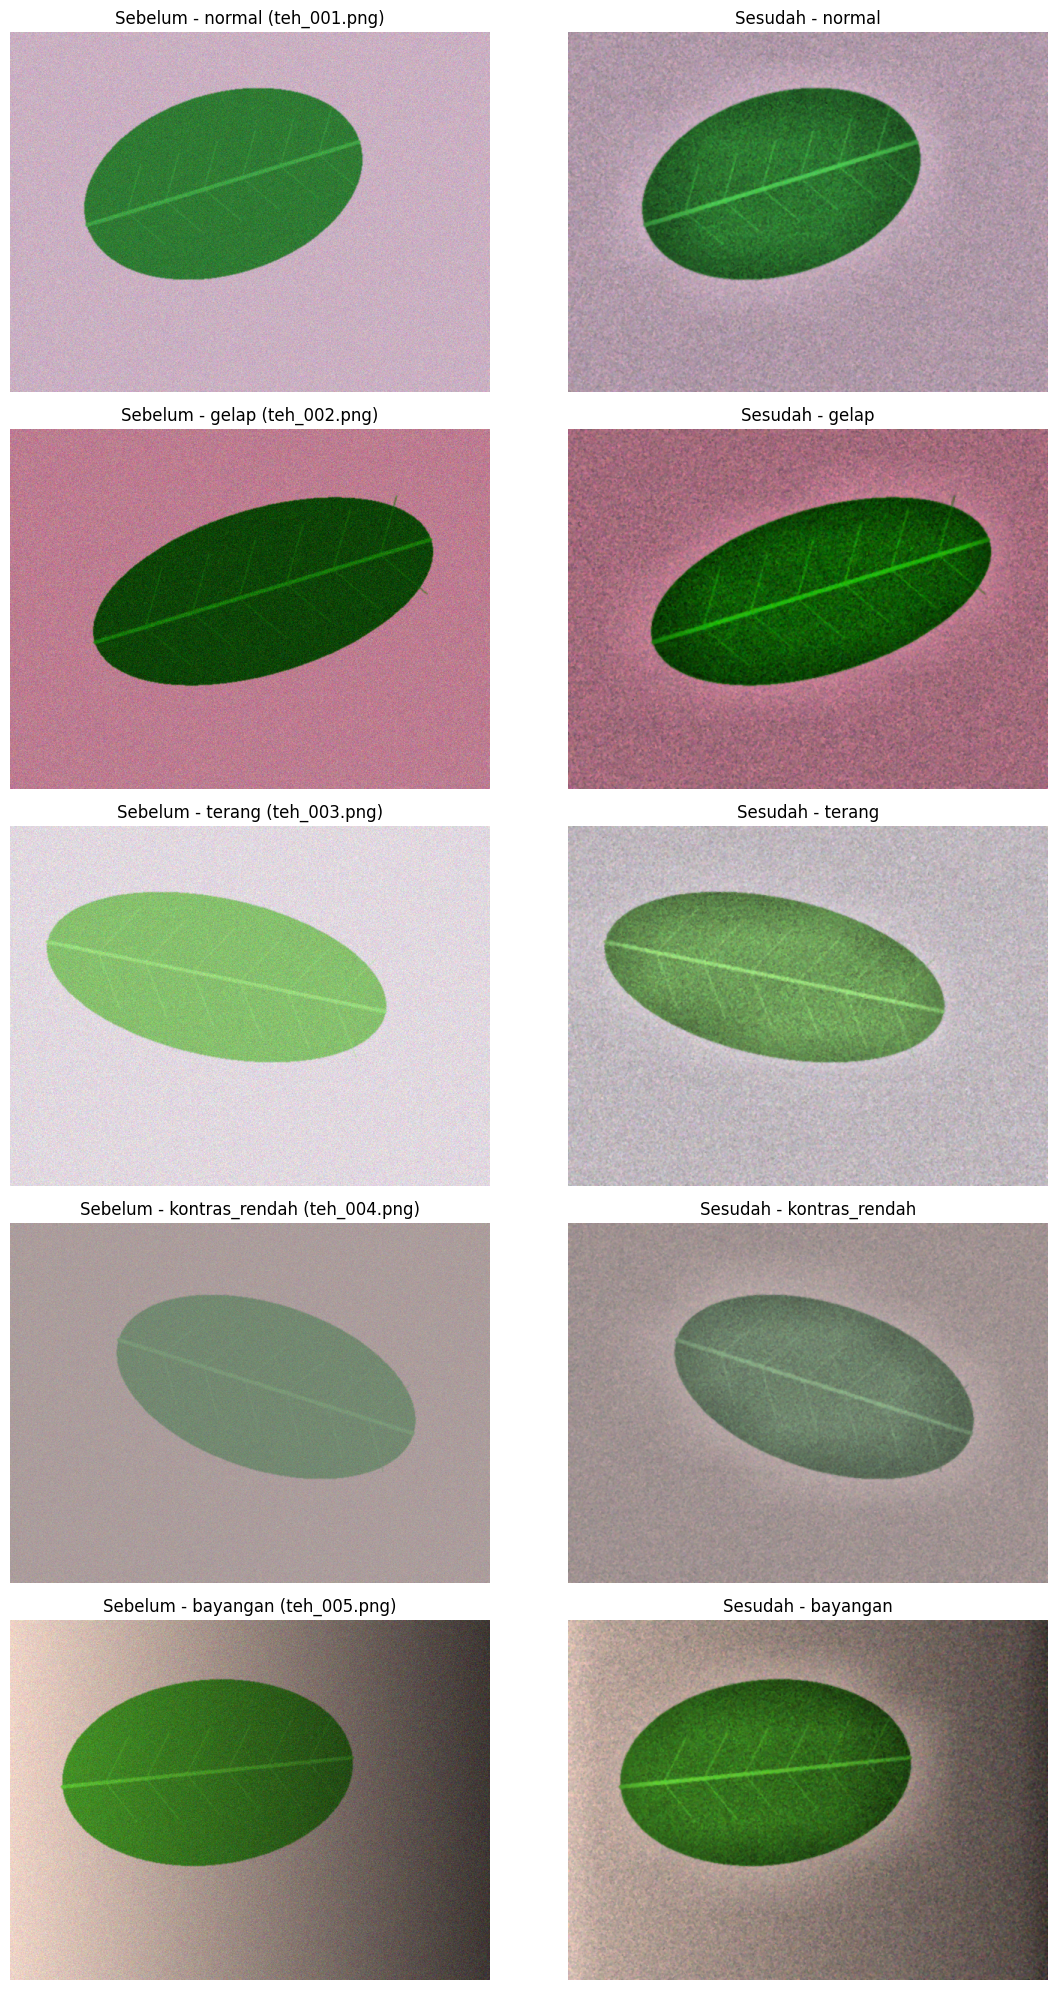

In [11]:
urutan = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

fig, axes = plt.subplots(5, 2, figsize=(12, 20))

for i, kondisi in enumerate(urutan):
    img, out, nama = contoh_per_kondisi[kondisi]

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    out_rgb = cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

    axes[i, 0].imshow(img_rgb)
    axes[i, 0].set_title(f"Sebelum - {kondisi} ({nama})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(out_rgb)
    axes[i, 1].set_title(f"Sesudah - {kondisi}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()